# Experimento 03 - Análise Temática de Diálogos

In [43]:
#pip install -r requirements.txt2

In [44]:
from langchain_openai import AzureChatOpenAI
from langchain_openai.embeddings import AzureOpenAIEmbeddings
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from dotenv import load_dotenv
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from tqdm import tqdm
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFLoader
from sklearn.metrics.pairwise import cosine_similarity

In [45]:
load_dotenv()

llm = AzureChatOpenAI(
    model="gpt-4o", 
    openai_api_version=os.getenv("AZURE_OPENAI_API_VERSION"),  
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY")
)

system_prompt = """
Você é um assistente inteligente que vai construir uma conversa entre duas personas. Considere que a conversa pode ser natural (pode ser como num formato de podcast). Seu trabalho e gerar uma conversa extensa que começa com tópicos relacionados à {topic_1}, mas que gradualmente se move para tópicos relacionados a {topic_2}.

Siga o seguinte padrão para a conversa:

Persona 1: [fala algo que pode ser relacionado a {topic_1}]
Persona 2: [responde, ainda relacionado a {topic_1} ou fazendo uma transição suave]
... 


---------------

Continue a conversa por pelo menos 100 trocas de mensagens
"""

prompt = ChatPromptTemplate.from_messages(
        [
            ("system", system_prompt),
            ("human", "Gere a conversa entre as duas personas."),
        ]
)

chain = prompt | llm | StrOutputParser()

In [46]:
response = chain.invoke({
    "topic_1": "história",
    "topic_2": "matemática"
})

In [47]:
def select_persona(message: str) -> str:
    if message.startswith("Persona 1:"):
        return "Persona 1"
    elif message.startswith("Persona 2:"):
        return "Persona 2"
    else:
        return "Unknown"

conversation_list = response.split("\n")
conversation_list = [line for line in conversation_list if line.strip() != ""]
conversation_list_persona = [{"persona": select_persona(line), "message": line[11:]} for line in conversation_list]

In [48]:
system_prompt_summary = """
Você é um assistente inteligente que vai resumir uma conversa entre duas personas. Você vai receber uma lista de mensagens, cada uma associada a uma persona (Persona 1 ou Persona 2). Seu trabalho é gerar um resumo conciso da conversa, dê enfase para o tópico principal discutido na conversa no momento atual (mesmo que o tópico tenha mudado ao longo da conversa). Os tópicos devem girar em torno de {topic_1} e {topic_2}.
"""

prompt_summary = ChatPromptTemplate.from_messages(
        [
            ("system", system_prompt_summary),
            ("human", "Resuma a conversa dada: {conversation}"),
        ]
)

chain_summary = prompt_summary | llm | StrOutputParser()

In [63]:
summary_list = []
buffer = []
for i in tqdm(range(len(conversation_list))):
    buffer.append(conversation_list[i])
    buffer_trimmed = buffer[-10:]  
    buffer_str = "\n".join(buffer_trimmed)
    response_summary = chain_summary.invoke({
        "topic_1": "história",
        "topic_2": "matemática",
        "conversation": buffer_str
    })
    summary_list.append(response_summary)

100%|██████████| 34/34 [01:07<00:00,  2.00s/it]


In [64]:
all_data_list = []
for i in range(len(conversation_list)):
    all_data_list.append({
        "summary": summary_list[i],
        "persona": conversation_list_persona[i]["persona"],
        "message": conversation_list_persona[i]["message"]
    })

os.makedirs("../data/conversation", exist_ok=True)

with open("../data/conversation/conversation_data.json", "w", encoding="utf-8") as f:
    json.dump(all_data_list, f, ensure_ascii=False, indent=4)

with open("../data/conversation/conversation_data.json", "r", encoding="utf-8") as f:
    loaded_content = json.load(f)   
    print(loaded_content[:5])

[{'summary': 'A conversa destaca a admiração pela organização e infraestrutura do Império Romano, ressaltando como a civilização conseguiu se manter por tanto tempo sem a tecnologia moderna.', 'persona': 'Unknown', 'message': ':** Sabe, estava lendo sobre o Império Romano esses dias. É impressionante como eles conseguiram manter uma civilização tão organizada e espalhada por tanto tempo. Quero dizer, não tinham a tecnologia que temos hoje, mas ainda assim criaram uma infraestrutura incrível.'}, {'summary': 'A conversa foca na admiração pelas realizações do Império Romano, destacando sua organização, infraestrutura e a durabilidade das estradas romanas, que facilitaram a comunicação e a movimentação de tropas de forma eficiente.', 'persona': 'Unknown', 'message': ':** Totalmente! As estradas romanas ainda me fascinam. Foram projetadas de forma tão inteligente que muitas delas ainda existem hoje. A logística daquele tempo era realmente impressionante, mantendo comunicações e tropas se mo

In [65]:
file_path_matematica = "pdfs2/MatematicaI.pdf"
file_path_historia   = "pdfs2/HistoriaI.pdf"

loader_historia   = PyPDFLoader(file_path_historia)
loader_matematica = PyPDFLoader(file_path_matematica)

pages_historia   = loader_historia.load()
pages_matematica = loader_matematica.load()

n_pages = 30
selected_historia   = pages_historia[:n_pages]
selected_matematica = pages_matematica[:n_pages]


In [66]:
embeddings = AzureOpenAIEmbeddings(
    model ="text-embedding-3-small",
    openai_api_version=os.getenv("AZURE_OPENAI_API_VERSION"),  
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY")
)


In [67]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=5000,
    chunk_overlap=1500,
    length_function=len,
    is_separator_regex=False,
)

chunks_historia = text_splitter.split_documents(selected_historia)
chunks_matematica = text_splitter.split_documents(selected_matematica)
len(chunks_historia), len(chunks_matematica)

(58, 32)

In [68]:
chunks_conversation = []
for item in loaded_content:
    chunks_conversation.append(item['summary'])
len(chunks_conversation)

34

In [69]:
vectors_conversation = np.array(embeddings.embed_documents([chunk for chunk in chunks_conversation]))
vectors_historia = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_historia]))
vectors_matematica = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_matematica]))
all_vectors = np.concatenate([vectors_conversation, vectors_historia, vectors_matematica], axis=0)
vectors_conversation.shape, vectors_matematica.shape, vectors_historia.shape, all_vectors.shape

((34, 1536), (32, 1536), (58, 1536), (124, 1536))

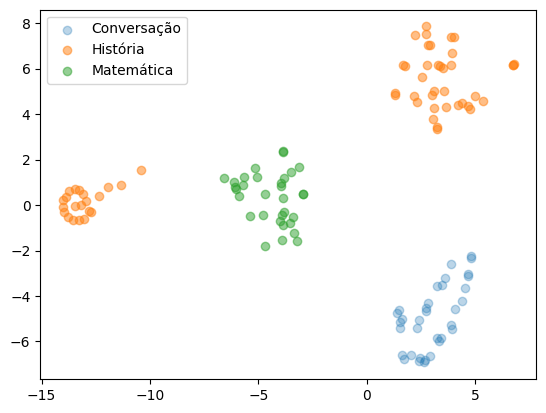

In [70]:
tsne = TSNE(n_components=2, random_state=42)
all_vectors_tsne = tsne.fit_transform(all_vectors)

plt.scatter(all_vectors_tsne[:len(vectors_conversation), 0], all_vectors_tsne[:len(vectors_conversation), 1], label="Conversação", alpha=0.3)

plt.scatter(all_vectors_tsne[len(vectors_conversation):len(vectors_historia) + len(vectors_conversation), 0], all_vectors_tsne[len(vectors_conversation):len(vectors_historia) + len(vectors_conversation), 1], label="História", alpha=0.5)
plt.scatter(all_vectors_tsne[len(vectors_historia) + len(vectors_conversation):, 0], all_vectors_tsne[len(vectors_historia) + len(vectors_conversation):, 1], label="Matemática", alpha=0.5)
plt.legend()
plt.show()

In [71]:
centroid_historia = np.mean(vectors_historia, axis=0)
centroid_matematica = np.mean(vectors_matematica, axis=0)

In [72]:
similarity_to_historia = cosine_similarity(vectors_conversation, centroid_historia.reshape(1, -1))
similarity_to_matematica = cosine_similarity(vectors_conversation, centroid_matematica.reshape(1, -1))
content_and_similarities = []
for i in range(len(chunks_conversation)):
    content_and_similarities.append({
        "chunk": chunks_conversation[i],
        "similarity_to_historia": similarity_to_historia[i, 0],
        "similarity_to_matematica": similarity_to_matematica[i, 0]
    })
df = pd.DataFrame(content_and_similarities)
df.sort_values(by="similarity_to_matematica", ascending=False).head(10)

,chunk,similarity_to_historia,similarity_to_matematica
22,A conversa gira em torno da conexão entre a ma...,0.313859,0.497491
33,A conversa gira em torno da importância e bele...,0.296091,0.497143
15,A conversa explora a evolução de conceitos mat...,0.378383,0.485242
28,A conversa explora como a matemática é a base ...,0.296864,0.484503
24,"A conversa foca na relação entre matemática, f...",0.279396,0.484274
16,A conversa discute ideias relacionadas ao impa...,0.359156,0.481748
26,A conversa gira em torno da interconexão entre...,0.326000,0.480022
32,A conversa gira em torno da importância e bele...,0.265214,0.479405
19,A conversa gira em torno da interseção entre m...,0.351462,0.473381
17,A conversa aborda como a matemática e a histór...,0.372559,0.471879


In [73]:
df.sort_values(by="similarity_to_historia", ascending=False).head(10)

,chunk,similarity_to_historia,similarity_to_matematica
8,A conversa gira em torno das contribuições his...,0.471889,0.430199
9,A conversa entre Persona 1 e Persona 2 gira em...,0.458394,0.400846
5,A conversa gira em torno das realizações do Im...,0.445604,0.400492
3,A conversa discute as realizações impressionan...,0.444786,0.377866
10,A conversa gira em torno de como os conhecimen...,0.436054,0.436747
7,A conversa gira em torno das realizações do Im...,0.435021,0.429711
2,A conversa está focada na impressionante organ...,0.432497,0.355917
4,A conversa explora as avançadas conquistas do ...,0.431462,0.364173
6,A conversa gira em torno das contribuições do ...,0.427189,0.413318
1,A conversa foca na admiração pelas realizações...,0.418791,0.286886


In [74]:
example_matematica = df.sort_values(by="similarity_to_matematica", ascending=False).head(10)['chunk'].values
for x in example_matematica:
    print(x)

A conversa gira em torno da conexão entre a matemática e suas aplicações práticas no mundo real. Os participantes discutem o impacto de conceitos matemáticos emblemáticos, como os limites no cálculo, a Teoria da Relatividade de Einstein, as equações de Maxwell e ferramentas como vetores e integrais, explorando como essas ideias moldaram áreas como física, engenharia e tecnologia. Destacam o papel da matemática em sistemas modernos, como satélites GPS, Wi-Fi e inteligência artificial, enfatizando sua influência em redes neurais que simulam o cérebro humano e na análise de sinais com transformadas de Fourier.
A conversa gira em torno da importância e beleza da matemática como a base de muitos avanços. As personas discutem como conceitos simples, como somar e subtrair, evoluíram para teorias complexas, sendo essenciais para áreas como álgebra, física quântica e a compreensão do universo. Eles destacam os fractais como exemplo de como fórmulas matemáticas geram formas complexas e utilitári

In [75]:
example_historia = df.sort_values(by="similarity_to_historia", ascending=False).head(10)['chunk'].values
for x in example_historia:
    print(x)

A conversa gira em torno das contribuições históricas e matemáticas de civilizações antigas, com foco inicial no Império Romano, destacando suas conquistas em engenharia, como estradas e aquedutos, e sua aplicação prática de geometria e álgebra. Em seguida, os participantes discutem a evolução dos sistemas numéricos, comparando os numerais romanos e o sistema decimal, e refletem sobre como heranças matemáticas, como o sistema sexagesimal dos babilônios, ainda influenciam o mundo moderno, especialmente na medição de tempo.
A conversa entre Persona 1 e Persona 2 gira em torno das contribuições históricas de civilizações antigas para a engenharia, ciência e matemática. Eles discutem a sofisticação do Império Romano, com destaque para estradas, aquedutos e o uso prático da geometria e álgebra. Também mencionam a evolução dos sistemas numéricos, comparando a complexidade dos números romanos com a simplicidade do sistema decimal, e exploram o impacto de heranças matemáticas de diferentes cul